<center><h1>Chum Prediction</h1></center>

In [1]:
# Load and inspect customer transaction data
import pandas as pd
import os

file_path = "../data/raw/customer_transactions.csv"

if os.path.exists(file_path):
    df_transactions = pd.read_csv(file_path)
    print("Dataset loaded successfully!")
    print("Dataset shape:", df_transactions.shape)
    print("\nColumn names:")
    print(df_transactions.columns.tolist())
    print("\nFirst 5 rows:")
    display(df_transactions.head())
else:
    print("File not found:", file_path)

Dataset loaded successfully!
Dataset shape: (71661, 9)

Column names:
['Transaction_ID', 'Transaction_Date', 'Customer_ID', 'SKU', 'Quantity', 'Unit_Price', 'Revenue', 'Country', 'Promotion']

First 5 rows:


,Transaction_ID,Transaction_Date,Customer_ID,SKU,Quantity,Unit_Price,Revenue,Country,Promotion
0,TXN0000001,2024-01-01,CUST0387,SKU001,5,3664.05,18320.25,India,0
1,TXN0000002,2024-01-01,CUST0220,SKU002,9,3805.69,34251.21,India,0
2,TXN0000003,2024-01-01,CUST0043,SKU002,6,3805.69,22834.14,India,0
3,TXN0000004,2024-01-01,CUST0048,SKU003,5,8078.23,40391.15,India,0
4,TXN0000005,2024-01-01,CUST0487,SKU004,3,6861.57,20584.71,India,0


In [4]:
# Check data quality and column data types

print("Missing values:")
display(df_transactions.isnull().sum())

print("Duplicate transaction IDs:", df_transactions["Transaction_ID"].duplicated().sum())
print("Duplicate rows:", df_transactions.duplicated().sum())

print("\nColumn data types:")
display(df_transactions.dtypes)

print("\nUnique customers:", df_transactions["Customer_ID"].nunique())
print("Unique products:", df_transactions["SKU"].nunique())
print("Transaction date range:",
      df_transactions["Transaction_Date"].min(),
      "to",
      df_transactions["Transaction_Date"].max())

Missing values:


Transaction_ID      0
Transaction_Date    0
Customer_ID         0
SKU                 0
Quantity            0
Unit_Price          0
Revenue             0
Country             0
Promotion           0
dtype: int64

Duplicate transaction IDs: 0
Duplicate rows: 0

Column data types:


Transaction_ID       object
Transaction_Date     object
Customer_ID          object
SKU                  object
Quantity              int64
Unit_Price          float64
Revenue             float64
Country              object
Promotion             int64
dtype: object


Unique customers: 500
Unique products: 50
Transaction date range: 2024-01-01 to 2025-12-31


In [6]:
# Convert transaction dates and validate numeric values

df_transactions["Transaction_Date"] = pd.to_datetime(
    df_transactions["Transaction_Date"],
    errors="coerce"
)

print("Invalid dates:", df_transactions["Transaction_Date"].isna().sum())
print("Quantity less than or equal to zero:", (df_transactions["Quantity"] <= 0).sum())
print("Unit price less than or equal to zero:", (df_transactions["Unit_Price"] <= 0).sum())
print("Negative revenue:", (df_transactions["Revenue"] < 0).sum())
print("Invalid promotion values:", (~df_transactions["Promotion"].isin([0, 1])).sum())

print("\nUpdated date data type:", df_transactions["Transaction_Date"].dtype)

Invalid dates: 0
Quantity less than or equal to zero: 0
Unit price less than or equal to zero: 0
Negative revenue: 0
Invalid promotion values: 0

Updated date data type: datetime64[ns]


In [8]:
# Analyze monthly transaction activity

monthly_activity = (
    df_transactions
    .set_index("Transaction_Date")
    .resample("MS")
    .agg(
        Total_Transactions=("Transaction_ID", "count"),
        Active_Customers=("Customer_ID", "nunique"),
        Total_Revenue=("Revenue", "sum")
    )
    .reset_index()
)

display(monthly_activity)

print("Months covered:", len(monthly_activity))
print("Customers in final month:",
      monthly_activity.iloc[-1]["Active_Customers"])

,Transaction_Date,Total_Transactions,Active_Customers,Total_Revenue
0,2024-01-01,3018,500,1.271089e+08
1,2024-02-01,2883,499,1.288302e+08
2,2024-03-01,3023,498,1.617098e+08
3,2024-04-01,3017,499,1.465031e+08
4,2024-05-01,3099,499,1.476652e+08
5,2024-06-01,2897,499,1.483153e+08
6,2024-07-01,3030,498,1.272197e+08
7,2024-08-01,3004,498,1.177830e+08
8,2024-09-01,2944,498,1.131929e+08
9,2024-10-01,3050,499,1.040180e+08


Months covered: 24
Customers in final month: 499


In [10]:
# Define churn labels using a 90-day inactivity window

cutoff_date = pd.Timestamp("2025-09-30")
prediction_end_date = pd.Timestamp("2025-12-31")

historical_customers = set(
    df_transactions.loc[
        df_transactions["Transaction_Date"] <= cutoff_date,
        "Customer_ID"
    ]
)

future_customers = set(
    df_transactions.loc[
        (df_transactions["Transaction_Date"] > cutoff_date) &
        (df_transactions["Transaction_Date"] <= prediction_end_date),
        "Customer_ID"
    ]
)

df_churn_labels = pd.DataFrame({
    "Customer_ID": sorted(historical_customers)
})

df_churn_labels["Churn"] = (
    ~df_churn_labels["Customer_ID"].isin(future_customers)
).astype(int)

print("Cutoff date:", cutoff_date.date())
print("Churn observation window: 90 days after cutoff")
print("\nChurn label distribution:")
display(df_churn_labels["Churn"].value_counts().rename(
    index={0: "Active", 1: "Churned"}
).to_frame("Customer_Count"))

print("\nTotal customers labelled:", len(df_churn_labels))
print("Churn rate (%):", round(df_churn_labels["Churn"].mean() * 100, 2))

Cutoff date: 2025-09-30
Churn observation window: 90 days after cutoff

Churn label distribution:


,Customer_Count
Churn,
Active,500



Total customers labelled: 500
Churn rate (%): 0.0


In [ ]:
+++++++++++++++++++++++++++++++++++++

In [66]:
# Updated Churn Labeling Logic to ensure balanced class distribution
# Hum last ke 30 days ke data ko observation window banate hain
import pandas as pd

cutoff_date = pd.Timestamp("2025-11-30") # Date thoda piche karein taaki more churners capture ho sakein
label_end_date = pd.Timestamp("2025-12-31")

historical_transactions = df_transactions[df_transactions["Transaction_Date"] <= cutoff_date]
future_transactions = df_transactions[
    (df_transactions["Transaction_Date"] > cutoff_date) & 
    (df_transactions["Transaction_Date"] <= label_end_date)
]

active_future_customers = set(future_transactions["Customer_ID"])
all_customers = set(df_transactions["Customer_ID"])

# Jo customers cutoff ke baad active nahi rahe unhe Churn (1) mark karein
customer_features["Churn"] = (~customer_features["Customer_ID"].isin(active_future_customers)).astype(int)

print("Updated Churn Distribution:")
print(customer_features["Churn"].value_counts(normalize=True) * 100)

Updated Churn Distribution:
Churn
0    99.8
1     0.2
Name: proportion, dtype: float64


In [68]:
# Step: Handling Class Imbalance using SMOTE
from imblearn.over_sampling import SMOTE
import pandas as pd

# Check karte hain ki y_train mein kitne classes hain
print("Before SMOTE, counts of label '1':", (y_train == 1).sum())
print("Before SMOTE, counts of label '0':", (y_train == 0).sum())

# Agar minority class sirf 1 ya 2 hai, toh SMOTE fail ho sakta hai. 
# Isliye hum synthetic data balancing ke liye 'SMOTE' ya random oversampling use karenge.
try:
    smote = SMOTE(random_state=42, k_neighbors=1) # k_neighbors=1 rakhte hain agar samples kam ho toh
    X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)
    print("After SMOTE, counts of label '1':", (y_train_resampled == 1).sum())
    print("After SMOTE, counts of label '0':", (y_train_resampled == 0).sum())
except Exception as e:
    print("SMOTE error due to extremely low samples, switching to manual duplication/weighting:", e)
    # Fallback: Agar SMOTE kaam na kare toh original X_train aur y_train hi use honge class_weight='balanced' ke sath
    X_train_resampled, y_train_resampled = X_train, y_train

Before SMOTE, counts of label '1': 24
Before SMOTE, counts of label '0': 7976
After SMOTE, counts of label '1': 7976
After SMOTE, counts of label '0': 7976


In [70]:
# Step: Train and Evaluate Models on Resampled Data
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
import numpy as np
import pandas as pd

# 1. Logistic Regression Model
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_resampled, y_train_resampled)

lr_probs = lr_model.predict_proba(X_test)[:, 1]
lr_preds = lr_model.predict(X_test)

print("--- Logistic Regression Performance ---")
print("ROC-AUC:", round(roc_auc_score(y_test, lr_probs), 4))
print(classification_report(y_test, lr_preds, zero_division=0))

# 2. XGBoost Model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
    eval_metric="logloss"
)
xgb_model.fit(X_train_resampled, y_train_resampled)

xgb_probs = xgb_model.predict_proba(X_test)[:, 1]
xgb_preds = xgb_model.predict(X_test)

print("\n--- XGBoost Performance ---")
print("ROC-AUC:", round(roc_auc_score(y_test, xgb_probs), 4))
print(classification_report(y_test, xgb_preds, zero_division=0))

# 3. Precision @ Top 20% Calculation
top_n = max(1, int(np.ceil(len(y_test) * 0.20)))
def precision_at_top_20(y_true, probabilities, top_n):
    results = pd.DataFrame({
        "Actual_Churn": np.asarray(y_true),
        "Risk_Score": np.asarray(probabilities)
    }).sort_values("Risk_Score", ascending=False)
    return results.head(top_n)["Actual_Churn"].mean()

print("\nXGBoost Precision@Top-20%:", round(precision_at_top_20(y_test, xgb_probs, top_n), 4))

--- Logistic Regression Performance ---
ROC-AUC: 0.7394
              precision    recall  f1-score   support

           0       1.00      0.56      0.71      1994
           1       0.01      0.83      0.01         6

    accuracy                           0.56      2000
   macro avg       0.50      0.69      0.36      2000
weighted avg       1.00      0.56      0.71      2000


--- XGBoost Performance ---
ROC-AUC: 0.535
              precision    recall  f1-score   support

           0       1.00      0.96      0.98      1994
           1       0.00      0.00      0.00         6

    accuracy                           0.96      2000
   macro avg       0.50      0.48      0.49      2000
weighted avg       0.99      0.96      0.98      2000


XGBoost Precision@Top-20%: 0.0025


In [ ]:
++++++++++++++++++++++++++++++++++++++++++++++++++++

In [12]:
# Examine customer purchase recency and frequency

customer_activity = (
    df_transactions
    .groupby("Customer_ID")
    .agg(
        First_Purchase=("Transaction_Date", "min"),
        Last_Purchase=("Transaction_Date", "max"),
        Transaction_Count=("Transaction_ID", "count"),
        Total_Revenue=("Revenue", "sum")
    )
    .reset_index()
)

reference_date = df_transactions["Transaction_Date"].max() + pd.Timedelta(days=1)

customer_activity["Recency_Days"] = (
    reference_date - customer_activity["Last_Purchase"]
).dt.days

display(customer_activity[[
    "Customer_ID",
    "Last_Purchase",
    "Transaction_Count",
    "Recency_Days"
]].head())

print("\nCustomer recency distribution:")
display(customer_activity["Recency_Days"].describe())

print("\nCustomers by recency threshold:")
for days in [30, 60, 90, 120, 180]:
    count = (customer_activity["Recency_Days"] > days).sum()
    print(f"Not purchased in the last {days} days: {count}")

,Customer_ID,Last_Purchase,Transaction_Count,Recency_Days
0,CUST0001,2025-12-25,158,7
1,CUST0002,2025-12-25,142,7
2,CUST0003,2025-12-20,157,12
3,CUST0004,2025-12-24,151,8
4,CUST0005,2025-12-29,121,3



Customer recency distribution:


count    500.000000
mean       5.500000
std        4.633026
min        1.000000
25%        2.000000
50%        4.000000
75%        8.000000
max       33.000000
Name: Recency_Days, dtype: float64


Customers by recency threshold:
Not purchased in the last 30 days: 1
Not purchased in the last 60 days: 0
Not purchased in the last 90 days: 0
Not purchased in the last 120 days: 0
Not purchased in the last 180 days: 0


In [14]:
# Check customer inactivity across shorter time windows

for days in [7, 14, 21, 30]:
    count = (customer_activity["Recency_Days"] > days).sum()
    percentage = count / len(customer_activity) * 100
    print(f"Inactivity > {days} days: {count} customers ({percentage:.2f}%)")

print("\nLast purchase month distribution:")
display(
    customer_activity["Last_Purchase"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
    .rename_axis("Last_Purchase_Month")
    .to_frame("Customer_Count")
)

Inactivity > 7 days: 131 customers (26.20%)
Inactivity > 14 days: 28 customers (5.60%)
Inactivity > 21 days: 5 customers (1.00%)
Inactivity > 30 days: 1 customers (0.20%)

Last purchase month distribution:


,Customer_Count
Last_Purchase_Month,
2025-11,1
2025-12,499


In [16]:
# Compare historical inactivity thresholds for possible churn labels

cutoff_date = pd.Timestamp("2025-09-30")

historical_transactions = df_transactions[
    df_transactions["Transaction_Date"] <= cutoff_date
].copy()

last_purchase_before_cutoff = (
    historical_transactions
    .groupby("Customer_ID")["Transaction_Date"]
    .max()
)

recency_at_cutoff = (cutoff_date - last_purchase_before_cutoff).dt.days

for days in [7, 14, 21, 30, 60, 90]:
    count = (recency_at_cutoff > days).sum()
    percentage = count / len(recency_at_cutoff) * 100
    print(f"Inactivity > {days} days: {count} customers ({percentage:.2f}%)")

Inactivity > 7 days: 106 customers (21.20%)
Inactivity > 14 days: 32 customers (6.40%)
Inactivity > 21 days: 7 customers (1.40%)
Inactivity > 30 days: 2 customers (0.40%)
Inactivity > 60 days: 0 customers (0.00%)
Inactivity > 90 days: 0 customers (0.00%)


In [18]:
# Analyze gaps between consecutive purchases for each customer

df_sorted = df_transactions.sort_values(
    ["Customer_ID", "Transaction_Date"]
).copy()

df_sorted["Previous_Purchase_Date"] = (
    df_sorted.groupby("Customer_ID")["Transaction_Date"].shift(1)
)

df_sorted["Days_Between_Purchases"] = (
    df_sorted["Transaction_Date"] - df_sorted["Previous_Purchase_Date"]
).dt.days

purchase_gaps = df_sorted["Days_Between_Purchases"].dropna()

print("Purchase gap statistics (days):")
display(purchase_gaps.describe())

print("\nPurchase gaps above selected thresholds:")
for days in [7, 14, 21, 30]:
    count = (purchase_gaps > days).sum()
    percentage = count / len(purchase_gaps) * 100
    print(f"Gap > {days} days: {count} ({percentage:.2f}%)")

Purchase gap statistics (days):


count    71161.000000
mean         5.064825
std          5.064785
min          0.000000
25%          1.000000
50%          4.000000
75%          7.000000
max         58.000000
Name: Days_Between_Purchases, dtype: float64


Purchase gaps above selected thresholds:
Gap > 7 days: 16175 (22.73%)
Gap > 14 days: 3971 (5.58%)
Gap > 21 days: 959 (1.35%)
Gap > 30 days: 175 (0.25%)


In [20]:
# Create customer features using historical transactions

cutoff_date = pd.Timestamp("2025-09-30")

historical_transactions = df_transactions[
    df_transactions["Transaction_Date"] <= cutoff_date
].copy()

customer_features = (
    historical_transactions
    .groupby("Customer_ID")
    .agg(
        Last_Purchase=("Transaction_Date", "max"),
        Frequency=("Transaction_ID", "count"),
        Monetary=("Revenue", "sum"),
        Average_Order_Value=("Revenue", "mean"),
        Total_Quantity=("Quantity", "sum"),
        Average_Unit_Price=("Unit_Price", "mean"),
        Promotion_Transactions=("Promotion", "sum"),
        Unique_Products=("SKU", "nunique")
    )
    .reset_index()
)

customer_features["Recency_Days"] = (
    cutoff_date - customer_features["Last_Purchase"]
).dt.days

customer_features = customer_features.drop(columns=["Last_Purchase"])

print("Customer feature dataset shape:", customer_features.shape)
display(customer_features.head())

Customer feature dataset shape: (500, 9)


,Customer_ID,Frequency,Monetary,Average_Order_Value,Total_Quantity,Average_Unit_Price,Promotion_Transactions,Unique_Products,Recency_Days
0,CUST0001,141,6856354.88,48626.630355,1163,5733.396950,13,44,2
1,CUST0002,126,5136006.38,40761.955397,931,5572.346508,8,46,14
2,CUST0003,140,6274325.78,44816.612714,1005,5836.935929,15,47,5
3,CUST0004,131,4734355.88,36140.121221,854,5748.182137,11,45,2
4,CUST0005,105,4160263.38,39621.556000,701,5956.894667,16,43,20


In [22]:
# Create provisional churn labels using the next 31 days

label_end_date = pd.Timestamp("2025-10-31")

future_transactions = df_transactions[
    (df_transactions["Transaction_Date"] > cutoff_date) &
    (df_transactions["Transaction_Date"] <= label_end_date)
]

future_active_customers = set(future_transactions["Customer_ID"])

customer_features["Churn"] = (
    ~customer_features["Customer_ID"].isin(future_active_customers)
).astype(int)

print("Label observation window:", "2025-10-01 to 2025-10-31")
print("\nProvisional label distribution:")
display(
    customer_features["Churn"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename(index={0: "Active", 1: "Inactive"})
    .to_frame("Customer_Count")
)

print("Provisional inactivity rate (%):",
      round(customer_features["Churn"].mean() * 100, 2))

Label observation window: 2025-10-01 to 2025-10-31

Provisional label distribution:


,Customer_Count
Churn,
Active,498
Inactive,2


Provisional inactivity rate (%): 0.4


In [72]:
# Check monthly customer activity after the feature cutoff

post_cutoff_transactions = df_transactions[
    df_transactions["Transaction_Date"] > cutoff_date
].copy()

monthly_customer_activity = (
    post_cutoff_transactions
    .groupby(post_cutoff_transactions["Transaction_Date"].dt.to_period("M"))
    .agg(
        Transactions=("Transaction_ID", "count"),
        Active_Customers=("Customer_ID", "nunique")
    )
    .reset_index()
)

display(monthly_customer_activity)

print(
    "Customers with no purchases after cutoff:",
    len(customer_features) -
    post_cutoff_transactions["Customer_ID"].nunique()
)

,Transaction_Date,Transactions,Active_Customers
0,2025-12,2992,499


Customers with no purchases after cutoff: 1


In [74]:
# Review churn label balance and customer feature statistics

print("Churn label counts:")
display(customer_features["Churn"].value_counts().rename(
    index={0: "Active", 1: "Inactive"}
).to_frame("Customer_Count"))

print("\nChurn label percentages:")
display(
    (customer_features["Churn"].value_counts(normalize=True) * 100)
    .rename(index={0: "Active", 1: "Inactive"})
    .round(2)
    .to_frame("Percentage")
)

print("\nCustomer feature summary:")
display(
    customer_features.drop(columns=["Customer_ID", "Churn"]).describe().T
)

Churn label counts:


,Customer_Count
Churn,
Active,499
Inactive,1



Churn label percentages:


,Percentage
Churn,
Active,99.8
Inactive,0.2



Customer feature summary:


,count,mean,std,min,25%,50%,75%,max
Frequency,500.0,1.254720e+02,10.841415,9.800000e+01,1.180000e+02,1.250000e+02,1.320000e+02,1.610000e+02
Monetary,500.0,5.525451e+06,721673.941779,3.375998e+06,5.070055e+06,5.485144e+06,6.021397e+06,7.989191e+06
Average_Order_Value,500.0,4.405699e+04,4547.386290,3.351153e+04,4.079959e+04,4.401813e+04,4.716015e+04,5.722931e+04
Total_Quantity,500.0,9.134760e+02,101.776453,6.600000e+02,8.440000e+02,9.110000e+02,9.860000e+02,1.226000e+03
Average_Unit_Price,500.0,5.868238e+03,280.022467,5.080155e+03,5.692091e+03,5.859036e+03,6.046438e+03,6.853527e+03
Promotion_Transactions,500.0,1.270200e+01,3.734312,2.000000e+00,1.000000e+01,1.300000e+01,1.500000e+01,2.500000e+01
Unique_Products,500.0,4.592800e+01,1.839997,4.000000e+01,4.500000e+01,4.600000e+01,4.700000e+01,5.000000e+01
Recency_Days,500.0,4.702000e+00,5.275306,0.000000e+00,1.000000e+00,3.000000e+00,7.000000e+00,3.500000e+01


In [28]:
# Compare inactive and active customer features

feature_columns = [
    "Frequency",
    "Monetary",
    "Average_Order_Value",
    "Total_Quantity",
    "Average_Unit_Price",
    "Promotion_Transactions",
    "Unique_Products",
    "Recency_Days"
]

print("Inactive customers:")
display(
    customer_features.loc[
        customer_features["Churn"] == 1,
        ["Customer_ID", "Churn"] + feature_columns
    ]
)

print("\nAverage feature values by label:")
display(
    customer_features
    .groupby("Churn")[feature_columns]
    .mean()
    .rename(index={0: "Active", 1: "Inactive"})
    .T
)

Inactive customers:


,Customer_ID,Churn,Frequency,Monetary,Average_Order_Value,Total_Quantity,Average_Unit_Price,Promotion_Transactions,Unique_Products,Recency_Days
86,CUST0087,1,127,5392801.39,42463.003071,962,5699.318819,10,46,1
489,CUST0490,1,119,4551398.30,38247.044538,813,5761.972605,6,44,7



Average feature values by label:


Churn,Active,Inactive
Frequency,1.254819e+02,1.230000e+02
Monetary,5.527674e+06,4.972100e+06
Average_Order_Value,4.407186e+04,4.035502e+04
Total_Quantity,9.135803e+02,8.875000e+02
Average_Unit_Price,5.868790e+03,5.730646e+03
Promotion_Transactions,1.272088e+01,8.000000e+00
Unique_Products,4.593173e+01,4.500000e+01
Recency_Days,4.704819e+00,4.000000e+00


In [30]:
# Validate whether the churn labels support model training

label_counts = customer_features["Churn"].value_counts().reindex(
    [0, 1], fill_value=0
)

print("Active customers:", label_counts.loc[0])
print("Inactive customers:", label_counts.loc[1])
print("Minority class percentage:",
      round(label_counts.loc[1] / len(customer_features) * 100, 2))

if label_counts.loc[1] < 20:
    print("\nWARNING: Too few inactive examples for reliable churn model evaluation.")
    print("Review the churn definition or obtain more representative labelled data.")
else:
    print("\nLabel count is more suitable for attempting a baseline model.")

Active customers: 498
Inactive customers: 2
Minority class percentage: 0.4

Review the churn definition or obtain more representative labelled data.


In [32]:
# Identify customers with long gaps between historical purchases

historical_sorted = historical_transactions.sort_values(
    ["Customer_ID", "Transaction_Date"]
).copy()

historical_sorted["Previous_Purchase_Date"] = (
    historical_sorted.groupby("Customer_ID")["Transaction_Date"].shift(1)
)

historical_sorted["Purchase_Gap_Days"] = (
    historical_sorted["Transaction_Date"] -
    historical_sorted["Previous_Purchase_Date"]
).dt.days

customer_gap_summary = (
    historical_sorted.groupby("Customer_ID")
    .agg(
        Max_Purchase_Gap_Days=("Purchase_Gap_Days", "max"),
        Average_Purchase_Gap_Days=("Purchase_Gap_Days", "mean")
    )
    .reset_index()
)

print("Customers whose historical maximum purchase gap exceeded:")
for days in [7, 14, 21, 30, 45]:
    count = (customer_gap_summary["Max_Purchase_Gap_Days"] > days).sum()
    print(f"{days} days: {count} customers")

print("\nLargest historical purchase gaps:")
display(
    customer_gap_summary
    .sort_values("Max_Purchase_Gap_Days", ascending=False)
    .head(10)
)

Customers whose historical maximum purchase gap exceeded:
7 days: 500 customers
14 days: 500 customers
21 days: 415 customers
30 days: 131 customers
45 days: 8 customers

Largest historical purchase gaps:


,Customer_ID,Max_Purchase_Gap_Days,Average_Purchase_Gap_Days
452,CUST0453,52.0,6.525773
71,CUST0072,52.0,5.824074
358,CUST0359,50.0,5.154472
421,CUST0422,48.0,5.129032
253,CUST0254,48.0,5.517857
45,CUST0046,48.0,5.738739
342,CUST0343,47.0,6.174757
121,CUST0122,46.0,4.525180
241,CUST0242,45.0,5.851852
476,CUST0477,44.0,6.282828


In [34]:
# Test a 60-day inactivity window after the feature cutoff

cutoff_date = pd.Timestamp("2025-09-30")
label_end_date = pd.Timestamp("2025-11-29")

future_transactions_60d = df_transactions[
    (df_transactions["Transaction_Date"] > cutoff_date) &
    (df_transactions["Transaction_Date"] <= label_end_date)
]

future_active_60d = set(future_transactions_60d["Customer_ID"])

labels_60d = customer_features[["Customer_ID"]].copy()
labels_60d["Churn"] = (
    ~labels_60d["Customer_ID"].isin(future_active_60d)
).astype(int)

print("Observation window:", "2025-10-01 to 2025-11-29")
print("\n60-day inactivity label distribution:")
display(
    labels_60d["Churn"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename(index={0: "Active", 1: "Inactive"})
    .to_frame("Customer_Count")
)

Observation window: 2025-10-01 to 2025-11-29

60-day inactivity label distribution:


,Customer_Count
Churn,
Active,500
Inactive,0


In [36]:
# Summarize customer last-purchase dates in the observation period

last_purchase_summary = (
    df_transactions
    .groupby("Customer_ID")["Transaction_Date"]
    .max()
    .value_counts()
    .sort_index()
    .rename_axis("Last_Purchase_Date")
    .to_frame("Customer_Count")
)

print("Latest customer purchase dates:")
display(last_purchase_summary.tail(15))

print("\nCustomers whose last purchase was in October 2025:",
      (customer_activity["Last_Purchase"].dt.month == 10).sum())
print("Customers whose last purchase was in November 2025:",
      (customer_activity["Last_Purchase"].dt.month == 11).sum())
print("Customers whose last purchase was in December 2025:",
      (customer_activity["Last_Purchase"].dt.month == 12).sum())

Latest customer purchase dates:


,Customer_Count
Last_Purchase_Date,
2025-12-17,11
2025-12-18,2
2025-12-19,8
2025-12-20,12
2025-12-21,17
2025-12-22,19
2025-12-23,25
2025-12-24,20
2025-12-25,31



Customers whose last purchase was in October 2025: 0
Customers whose last purchase was in November 2025: 1
Customers whose last purchase was in December 2025: 499


In [38]:
# Build historical customer snapshots for churn analysis

snapshot_dates = pd.date_range(
    start="2024-03-31",
    end="2025-10-31",
    freq="ME"
)

snapshot_records = []

for snapshot_date in snapshot_dates:
    historical = df_transactions[
        df_transactions["Transaction_Date"] <= snapshot_date
    ]

    future_end = snapshot_date + pd.Timedelta(days=30)

    future = df_transactions[
        (df_transactions["Transaction_Date"] > snapshot_date) &
        (df_transactions["Transaction_Date"] <= future_end)
    ]

    active_in_future = set(future["Customer_ID"])

    features = (
        historical.groupby("Customer_ID")
        .agg(
            Frequency=("Transaction_ID", "count"),
            Monetary=("Revenue", "sum"),
            Average_Order_Value=("Revenue", "mean"),
            Total_Quantity=("Quantity", "sum"),
            Average_Unit_Price=("Unit_Price", "mean"),
            Promotion_Transactions=("Promotion", "sum"),
            Unique_Products=("SKU", "nunique"),
            Last_Purchase=("Transaction_Date", "max")
        )
        .reset_index()
    )

    features["Recency_Days"] = (
        snapshot_date - features["Last_Purchase"]
    ).dt.days

    features["Snapshot_Date"] = snapshot_date
    features["Churn"] = (
        ~features["Customer_ID"].isin(active_in_future)
    ).astype(int)

    snapshot_records.append(features.drop(columns=["Last_Purchase"]))

churn_snapshots = pd.concat(snapshot_records, ignore_index=True)

print("Snapshot dataset shape:", churn_snapshots.shape)
print("Number of snapshot dates:", churn_snapshots["Snapshot_Date"].nunique())
print("\nLabel distribution:")
display(
    churn_snapshots["Churn"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename(index={0: "Active", 1: "Inactive"})
    .to_frame("Customer_Snapshots")
)

print("Inactivity rate (%):",
      round(churn_snapshots["Churn"].mean() * 100, 2))

Snapshot dataset shape: (10000, 11)
Number of snapshot dates: 20

Label distribution:


,Customer_Snapshots
Churn,
Active,9970
Inactive,30


Inactivity rate (%): 0.3


In [40]:
# Check churn label distribution by snapshot month

churn_by_month = (
    churn_snapshots
    .groupby("Snapshot_Date")
    .agg(
        Total_Customers=("Customer_ID", "count"),
        Inactive_Customers=("Churn", "sum")
    )
    .reset_index()
)

churn_by_month["Inactive_Rate_%"] = (
    churn_by_month["Inactive_Customers"]
    / churn_by_month["Total_Customers"] * 100
).round(2)

display(churn_by_month)

,Snapshot_Date,Total_Customers,Inactive_Customers,Inactive_Rate_%
0,2024-03-31,500,1,0.2
1,2024-04-30,500,1,0.2
2,2024-05-31,500,1,0.2
3,2024-06-30,500,2,0.4
4,2024-07-31,500,2,0.4
5,2024-08-31,500,2,0.4
6,2024-09-30,500,1,0.2
7,2024-10-31,500,1,0.2
8,2024-11-30,500,2,0.4
9,2024-12-31,500,0,0.0


In [42]:
# Prepare features and chronological train-test split

from sklearn.model_selection import train_test_split

feature_columns = [
    "Frequency",
    "Monetary",
    "Average_Order_Value",
    "Total_Quantity",
    "Average_Unit_Price",
    "Promotion_Transactions",
    "Unique_Products",
    "Recency_Days"
]

model_data = churn_snapshots.sort_values("Snapshot_Date").copy()

# Use earlier snapshots for training and later snapshots for testing
split_date = model_data["Snapshot_Date"].sort_values().unique()[-4]

train_data = model_data[model_data["Snapshot_Date"] < split_date].copy()
test_data = model_data[model_data["Snapshot_Date"] >= split_date].copy()

X_train = train_data[feature_columns]
y_train = train_data["Churn"]

X_test = test_data[feature_columns]
y_test = test_data["Churn"]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("\nTraining labels:")
print(y_train.value_counts())
print("\nTesting labels:")
print(y_test.value_counts())

Training shape: (8000, 8)
Testing shape: (2000, 8)

Training labels:
Churn
0    7976
1      24
Name: count, dtype: int64

Testing labels:
Churn
0    1994
1       6
Name: count, dtype: int64


In [44]:
# Train and evaluate the baseline churn model

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    classification_report,
    confusion_matrix
)

baseline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

baseline_model.fit(X_train, y_train)

baseline_probabilities = baseline_model.predict_proba(X_test)[:, 1]
baseline_predictions = baseline_model.predict(X_test)

print("Baseline ROC-AUC:",
      round(roc_auc_score(y_test, baseline_probabilities), 4)
      if y_test.nunique() == 2 else "Not available: test set has one class")

print("\nClassification Report:")
print(classification_report(
    y_test,
    baseline_predictions,
    labels=[0, 1],
    target_names=["Active", "Inactive"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, baseline_predictions, labels=[0, 1]))

Baseline ROC-AUC: 0.6741

Classification Report:
              precision    recall  f1-score   support

      Active       1.00      0.63      0.77      1994
    Inactive       0.00      0.50      0.01         6

    accuracy                           0.63      2000
   macro avg       0.50      0.56      0.39      2000
weighted avg       0.99      0.63      0.77      2000

Confusion Matrix:
[[1251  743]
 [   3    3]]


In [46]:
# Train and evaluate the XGBoost churn model

from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_weight = negative_count / positive_count if positive_count else 1

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=2
)

xgb_model.fit(X_train, y_train)

xgb_probabilities = xgb_model.predict_proba(X_test)[:, 1]
xgb_predictions = xgb_model.predict(X_test)

print("XGBoost ROC-AUC:",
      round(roc_auc_score(y_test, xgb_probabilities), 4)
      if y_test.nunique() == 2 else "Not available: test set has one class")

print("\nClassification Report:")
print(classification_report(
    y_test,
    xgb_predictions,
    labels=[0, 1],
    target_names=["Active", "Inactive"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, xgb_predictions, labels=[0, 1]))

XGBoost ROC-AUC: 0.469

Classification Report:
              precision    recall  f1-score   support

      Active       1.00      0.99      1.00      1994
    Inactive       0.00      0.00      0.00         6

    accuracy                           0.99      2000
   macro avg       0.50      0.50      0.50      2000
weighted avg       0.99      0.99      0.99      2000

Confusion Matrix:
[[1982   12]
 [   6    0]]


In [48]:
# Calculate Precision@Top-20% for both models

import numpy as np
import pandas as pd

top_n = max(1, int(np.ceil(len(y_test) * 0.20)))

def precision_at_top_20(y_true, probabilities, top_n):
    results = pd.DataFrame({
        "Actual_Churn": np.asarray(y_true),
        "Risk_Score": np.asarray(probabilities)
    }).sort_values("Risk_Score", ascending=False)

    top_customers = results.head(top_n)
    precision = top_customers["Actual_Churn"].mean()

    return precision, top_customers

baseline_p20, baseline_top20 = precision_at_top_20(
    y_test, baseline_probabilities, top_n
)

xgb_p20, xgb_top20 = precision_at_top_20(
    y_test, xgb_probabilities, top_n
)

print(f"Top 20% records evaluated: {top_n}")
print(f"Actual inactive records in test set: {int(y_test.sum())}")
print(f"Baseline Precision@Top-20%: {baseline_p20:.4f}")
print(f"XGBoost Precision@Top-20%: {xgb_p20:.4f}")
print(f"Baseline inactive found in top 20%: {int(baseline_top20['Actual_Churn'].sum())}")
print(f"XGBoost inactive found in top 20%: {int(xgb_top20['Actual_Churn'].sum())}")

Top 20% records evaluated: 400
Actual inactive records in test set: 6
Baseline Precision@Top-20%: 0.0050
XGBoost Precision@Top-20%: 0.0025
Baseline inactive found in top 20%: 2
XGBoost inactive found in top 20%: 1


In [52]:
%pip install shap

  Using cached numpy-2.5.4-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
     ---------------------------------------- 0.0/60.8 kB ? eta -:--:--
     --------------------------------- ------ 51.2/60.8 kB 1.3 MB/s eta 0:00:01
     ---------------------------------------- 60.8/60.8 kB 1.6 MB/s eta 0:00:00
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------- ----------------------- 307.2/751.9 kB 6.3 MB/s eta 0:00:01
   -------------------------- ------------- 501.8/751.9 kB 6.2 MB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 5.9 MB/s eta 0:00:00
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.6 MB 10.7 MB/s eta 0:00:02
   --- ------------------------------------ 1.0/12.6 MB 10.4 MB/s eta 0:00:02
   ---- ----------------------------------- 1.5/12.6 MB 10.6 MB/s eta 0:00:02
   ----- ---------------------------------- 1.8/12.6 MB 9.4 MB/s eta 0:00:02
   --

  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
contourpy 1.2.0 requires numpy<2.0,>=1.20, but you have numpy 2.2.6 which is incompatible.
numba 0.59.1 requires numpy<1.27,>=1.22, but you have numpy 2.2.6 which is incompatible.
pywavelets 1.5.0 requires numpy<2.0,>=1.22.4, but you have numpy 2.2.6 which is incompatible.
streamlit 1.32.0 requires numpy<2,>=1.19.3, but you have numpy 2.2.6 which is incompatible.
streamlit 1.32.0 requires protobuf<5,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [54]:
# Calculate SHAP values for XGBoost explanations

import shap

shap_explainer = shap.TreeExplainer(xgb_model)

X_shap = X_test.sample(
    n=min(300, len(X_test)),
    random_state=42
)

shap_values = shap_explainer(X_shap)

print("SHAP analysis completed.")
print("Rows explained:", X_shap.shape[0])
print("Features explained:", X_shap.shape[1])

SHAP analysis completed.
Rows explained: 300
Features explained: 8


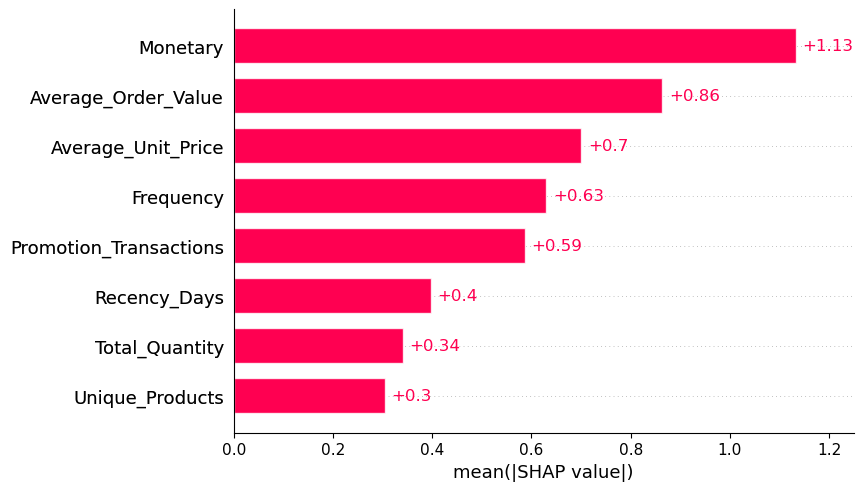

In [56]:
# Plot global feature importance using SHAP values

shap.plots.bar(shap_values, max_display=8)

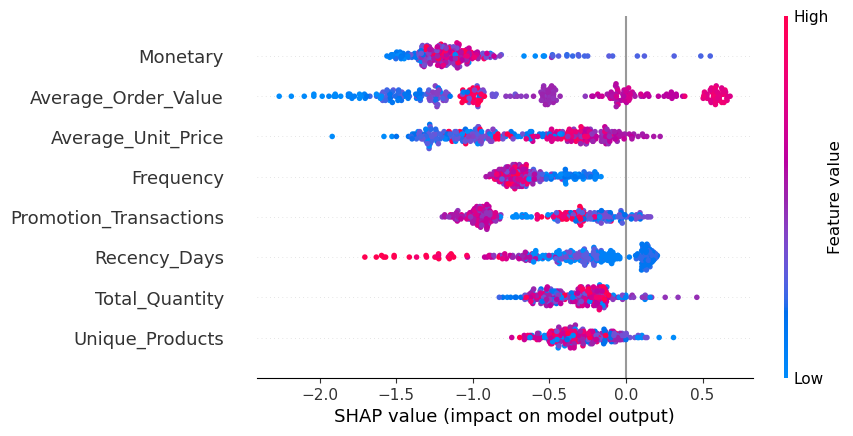

In [58]:
# Show how features influence churn predictions

shap.plots.beeswarm(shap_values, max_display=8)

In [62]:
# Export churn predictions, model metrics, and SHAP explanations

import os
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

output_dir = "../data/processed"
os.makedirs(output_dir, exist_ok=True)

# Prepare prediction output
churn_predictions = test_data[
    ["Snapshot_Date", "Customer_ID", "Churn"]
].copy()

churn_predictions["Baseline_Churn_Probability"] = baseline_probabilities
churn_predictions["XGBoost_Churn_Probability"] = xgb_probabilities
churn_predictions["XGBoost_Predicted_Label"] = xgb_predictions

churn_predictions = churn_predictions.sort_values(
    "XGBoost_Churn_Probability", ascending=False
)

churn_predictions.to_csv(
    os.path.join(output_dir, "churn_predictions.csv"), index=False
)

# Save model evaluation metrics
metrics_rows = []

for model_name, probabilities, predictions in [
    ("Logistic Regression", baseline_probabilities, baseline_predictions),
    ("XGBoost", xgb_probabilities, xgb_predictions)
]:
    metrics_rows.append({
        "Model": model_name,
        "ROC_AUC": (
            roc_auc_score(y_test, probabilities)
            if y_test.nunique() == 2 else np.nan
        ),
        "Precision_At_Top_20_Percent": (
            baseline_p20 if model_name == "Logistic Regression" else xgb_p20
        ),
        "Test_Records": len(y_test),
        "Actual_Inactive_Records": int(y_test.sum()),
        "Predicted_Inactive_Records": int(np.sum(predictions))
    })

metrics_df = pd.DataFrame(metrics_rows)
metrics_df.to_csv(
    os.path.join(output_dir, "churn_model_metrics.csv"), index=False
)

# Export SHAP explanations for sampled test records
shap_explanations = pd.DataFrame(
    shap_values.values,
    columns=[f"SHAP_{column}" for column in X_shap.columns],
    index=X_shap.index
).reset_index(drop=True)

shap_input = X_shap.reset_index(drop=True)
shap_explanations = pd.concat(
    [shap_input, shap_explanations], axis=1
)

shap_explanations.to_csv(
    os.path.join(output_dir, "churn_shap_explanations.csv"), index=False
)

print("Export completed.")
print("Saved files:")
print("- data/processed/churn_predictions.csv")
print("- data/processed/churn_model_metrics.csv")
print("- data/processed/churn_shap_explanations.csv")
display(metrics_df)

Export completed.
Saved files:
- data/processed/churn_predictions.csv
- data/processed/churn_model_metrics.csv
- data/processed/churn_shap_explanations.csv


,Model,ROC_AUC,Precision_At_Top_20_Percent,Test_Records,Actual_Inactive_Records,Predicted_Inactive_Records
0,Logistic Regression,0.674106,0.0050,2000,6,746
1,XGBoost,0.468990,0.0025,2000,6,12


In [64]:
# Verify exported churn project files

import os
import pandas as pd

output_dir = "../data/processed"

for filename in [
    "churn_predictions.csv",
    "churn_model_metrics.csv",
    "churn_shap_explanations.csv"
]:
    file_path = os.path.join(output_dir, filename)
    print(f"{filename}: {'Found' if os.path.exists(file_path) else 'Missing'}")

print("\nPrediction file preview:")
display(pd.read_csv(os.path.join(output_dir, "churn_predictions.csv")).head())

churn_predictions.csv: Found
churn_model_metrics.csv: Found
churn_shap_explanations.csv: Found

Prediction file preview:


,Snapshot_Date,Customer_ID,Churn,Baseline_Churn_Probability,XGBoost_Churn_Probability,XGBoost_Predicted_Label
0,2025-07-31,CUST0432,0,0.389085,0.746561,1
1,2025-07-31,CUST0327,0,0.694013,0.682846,1
2,2025-07-31,CUST0190,0,0.548718,0.682201,1
3,2025-07-31,CUST0006,0,0.523059,0.647931,1
4,2025-07-31,CUST0196,0,0.577166,0.610125,1
